# Lecture 2 — How does Machine Learning work?

**Companion notebook for Frankfurt UAS · Machine Learning · Winter semester 2026/27**

One complete walk-through, from raw data to a prediction:

1. **Load** real stock prices from an API (Financial Modeling Prep)
2. **Look** at the data before touching any model
3. **Turn** prices into *features* (X) and a *target* (y)
4. **Split** into training and test data — the right way for time series
5. **Train** a Random Forest
6. **Evaluate** honestly: against a dumb baseline, on data the model has never seen
7. **Predict** tomorrow

**The question we ask the machine:** *Will AAPL close higher tomorrow than today?*
That's a yes/no question, so this is a **classification** problem.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

from fmp_data import fetch_raw, load_prices

plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

SYMBOL = "AAPL"

---
## Step 1 — Load the data

`fetch_raw()` calls the FMP API once and caches the answer in `data/AAPL.json`.
The API key comes from the `.env` file (`FMP_API_KEY=...`) — **never** paste keys into a notebook.

### What does the API actually send back?

Web APIs answer in **JSON** (JavaScript Object Notation) — plain text that both humans and programs can read.
Let's look at the raw answer before we turn it into anything else:

In [2]:
raw = fetch_raw(SYMBOL, start="2015-01-01")

print(type(raw), "with", len(raw), "entries\n")
print(json.dumps(raw[:2], indent=2))   # only the first two days

Downloaded 2965 days for AAPL from FMP -> AAPL.json
<class 'list'> with 2965 entries

[
  {
    "symbol": "AAPL",
    "date": "2026-10-16",
    "open": 346.09,
    "high": 347.82,
    "low": 340.46,
    "close": 343.46,
    "volume": 59946368,
    "change": -2.62,
    "changePercent": -0.75992,
    "vwap": 344.4575
  },
  {
    "symbol": "AAPL",
    "date": "2026-10-15",
    "open": 346.95,
    "high": 347.85,
    "low": 341.6,
    "close": 342,
    "volume": 39767300,
    "change": -4.95,
    "changePercent": -1.43,
    "vwap": 344.6
  }
]


**How to read JSON:**

| Syntax | Meaning | In Python |
|---|---|---|
| `[ ... ]` | a **list** (array) — here: one entry per trading day | `list` |
| `{ ... }` | an **object** — a set of `"key": value` pairs | `dict` |
| `"AAPL"`, `"2026-10-16"` | text (string), always in double quotes | `str` |
| `343.46`, `59946368` | numbers | `float` / `int` |

So the whole answer is a **list of dicts**. Note that the **newest day comes first**.
In Python we access it like any list and dict:

In [3]:
first_day = raw[0]                 # first element of the list -> one dict
print(first_day["date"], "close:", first_day["close"])
print("keys:", list(first_day.keys()))

2026-10-16 close: 343.46
keys: ['symbol', 'date', 'open', 'high', 'low', 'close', 'volume', 'change', 'changePercent', 'vwap']


### From JSON to a table

A list of dicts with identical keys is basically a table: every dict is a **row**, every key a **column**.
`load_prices()` does exactly that with `pd.DataFrame(raw)` — plus sorting by date (oldest first)
and keeping only the columns we need.

In [4]:
prices = load_prices(SYMBOL, start="2015-01-01")
prices.head()

Loaded 2965 days for AAPL from cache (AAPL.json)


,open,high,low,close,volume
date,,,,,
2015-01-02,27.85,27.86,26.84,27.33,212818504
2015-01-05,27.07,27.16,26.35,26.56,257142000
2015-01-06,26.64,26.86,26.16,26.57,263188464
2015-01-07,26.80,27.05,26.67,26.94,160423736
2015-01-08,27.31,28.04,27.18,27.97,237458188


---
## Step 2 — Look at the data first

Rule #1 of ML: **never train a model on data you haven't looked at.**
How many rows? Any gaps? What do the numbers look like?

In [5]:
prices.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2965 entries, 2015-01-02 to 2026-10-16
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    2965 non-null   float64
 1   high    2965 non-null   float64
 2   low     2965 non-null   float64
 3   close   2965 non-null   float64
 4   volume  2965 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 139.0 KB


In [6]:
prices.describe().round(2)

,open,high,low,close,volume
count,2965.00,2965.00,2965.00,2965.00,2.965000e+03
mean,120.88,122.20,119.67,120.99,1.072394e+08
std,85.14,86.09,84.32,85.25,6.784106e+07
min,22.50,22.92,22.37,22.59,1.791060e+07
25%,40.68,41.06,40.09,40.73,5.914450e+07
50%,120.40,122.06,118.96,120.71,9.013142e+07
75%,180.67,182.43,178.33,180.71,1.336977e+08
max,346.95,348.15,341.72,343.46,6.488252e+08


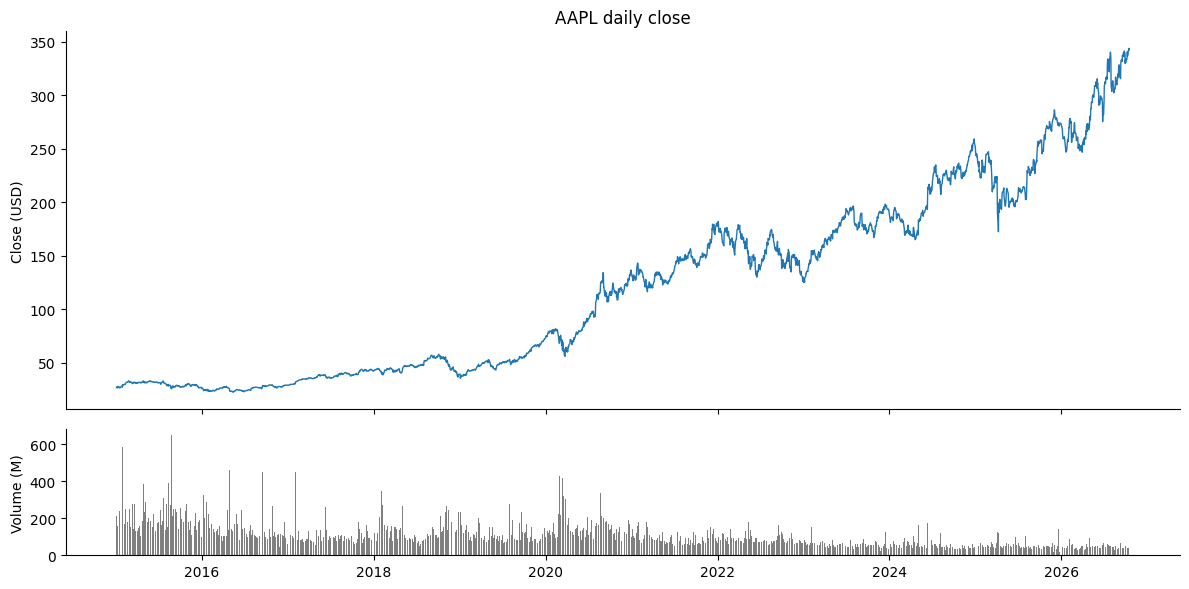

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, height_ratios=[3, 1])
axes[0].plot(prices.index, prices["close"], lw=1)
axes[0].set_ylabel("Close (USD)")
axes[0].set_title(f"{SYMBOL} daily close")
axes[1].bar(prices.index, prices["volume"] / 1e6, width=1, color="grey")
axes[1].set_ylabel("Volume (M)")
plt.tight_layout()
plt.show()

The price chart goes up a lot over 10 years. But a model that just learns *"the price is high"* is useless —
the price level in 2016 tells you nothing about 2026.

What we actually care about is the **daily change** (the *return*):

$$\text{return}_t = \frac{\text{close}_t}{\text{close}_{t-1}} - 1$$

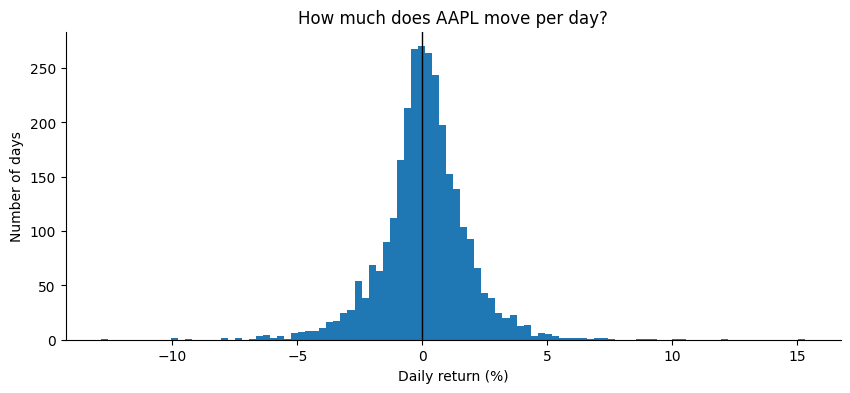

Days up:   52.9%
Days down: 47.1%


In [8]:
returns = prices["close"].pct_change().dropna()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(returns * 100, bins=100)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Daily return (%)")
ax.set_ylabel("Number of days")
ax.set_title("How much does AAPL move per day?")
plt.show()

print(f"Days up:   {(returns > 0).mean():.1%}")
print(f"Days down: {(returns <= 0).mean():.1%}")

**Two things to notice:**

- Most days the stock moves less than ±2 %. The distribution is centred almost exactly at zero.
- Up-days and down-days are close to **50 / 50** — but not exactly. Remember this number, we'll need it for the baseline.

---
## Step 3 — Features (X) and target (y)

A model can only learn from numbers we give it. Every row is **one trading day**:

- **Features (X):** things we know *at the end of today* — recent returns, volatility, distance to moving average, volume.
- **Target (y):** the thing we want to know — *does tomorrow close higher?* (1 = yes, 0 = no)

The crucial rule: **features may only use information up to today.** If tomorrow's price sneaks into X,
the model "cheats" (this is called *data leakage*) and looks brilliant — until it's used for real.

In [9]:
df = prices.copy()
close = df["close"]

# --- Features: everything computed from today and the past ---
df["return_1d"]  = close.pct_change(1)                       # today's move
df["return_5d"]  = close.pct_change(5)                       # last week's move
df["return_20d"] = close.pct_change(20)                      # last month's move
df["volatility_20d"] = df["return_1d"].rolling(20).std()     # how nervous is the market?
df["dist_sma_20"] = close / close.rolling(20).mean() - 1     # above/below 20-day average
df["dist_sma_50"] = close / close.rolling(50).mean() - 1     # above/below 50-day average
df["volume_ratio"] = df["volume"] / df["volume"].rolling(20).mean()  # unusual volume?

FEATURES = ["return_1d", "return_5d", "return_20d", "volatility_20d",
            "dist_sma_20", "dist_sma_50", "volume_ratio"]

# --- Target: tomorrow vs. today (shift(-1) looks ONE day into the future) ---
df["target"] = (close.shift(-1) > close).astype(int)

df[FEATURES + ["close", "target"]].tail(8).round(4)

,return_1d,return_5d,return_20d,volatility_20d,dist_sma_20,dist_sma_50,volume_ratio,close,target
date,,,,,,,,,
2026-10-07,0.0091,0.0110,0.0676,0.0128,0.0066,0.0447,0.8505,336.67,1
2026-10-08,0.0111,0.0306,0.0424,0.0106,0.0157,0.0561,0.9197,340.42,0
2026-10-09,-0.0111,0.0088,0.0132,0.0103,0.0037,0.0442,1.0028,336.64,1
2026-10-12,0.0129,0.0243,0.0237,0.0107,0.0154,0.0555,0.6980,340.97,1
2026-10-13,0.0009,0.0229,0.0300,0.0105,0.0148,0.0540,1.0405,341.27,1
2026-10-14,0.0050,0.0187,0.0317,0.0106,0.0183,0.0570,1.3115,342.96,0
2026-10-15,-0.0028,0.0046,0.0148,0.0102,0.0147,0.0521,1.0376,342.00,1
2026-10-16,0.0043,0.0203,0.0218,0.0102,0.0179,0.0545,1.6205,343.46,0


Look at the **last row**: today's features are known, but `target` is meaningless — tomorrow hasn't happened yet.
That row is exactly the one we want to *predict* at the end. So we put it aside.

The first ~50 rows have `NaN` features (a 50-day average needs 50 days of history) — we drop those.

In [10]:
latest_day = df[FEATURES].iloc[[-1]]          # the day we want to predict (target unknown)
data = df.iloc[:-1].dropna(subset=FEATURES)   # all days where we know the answer

X = data[FEATURES]
y = data["target"]
print(f"X: {X.shape[0]} days x {X.shape[1]} features")
print(f"y: {y.mean():.1%} of days are 'up' (1)")

X: 2915 days x 7 features
y: 52.7% of days are 'up' (1)


---
## Step 4 — Train / test split

We need data the model has **never seen** to find out if it learned something real or just memorised.

With stock data we **must not shuffle**: a random split would let the model train on next Tuesday
and be tested on this Monday — it would know the future. Instead we cut by **time**:

| | Period | Used for |
|---|---|---|
| Train | until end of 2023 | `fit()` — the model learns here |
| Test  | 2024 → today | `predict()` — the model is graded here |

In [11]:
SPLIT_DATE = "2024-01-01"

X_train, y_train = X[X.index <  SPLIT_DATE], y[y.index <  SPLIT_DATE]
X_test,  y_test  = X[X.index >= SPLIT_DATE], y[y.index >= SPLIT_DATE]

print(f"Train: {len(X_train)} days  ({X_train.index[0].date()} → {X_train.index[-1].date()})")
print(f"Test:  {len(X_test)} days  ({X_test.index[0].date()} → {X_test.index[-1].date()})")

Train: 2215 days  (2015-03-16 → 2023-12-29)
Test:  700 days  (2024-01-02 → 2026-10-15)


---
## Step 5 — The baseline: how good is "no intelligence at all"?

Before we train anything, we ask: **what accuracy do we get by always guessing the same thing?**

If most training days were "up", the dumbest possible model always says "up".
Any real model has to **beat this number** — otherwise it learned nothing.

In [12]:
majority_class = int(y_train.mean() >= 0.5)
baseline_pred = np.full(len(y_test), majority_class)
baseline_acc = accuracy_score(y_test, baseline_pred)

print(f"Baseline always predicts: {'up' if majority_class else 'down'}")
print(f"Baseline accuracy on test: {baseline_acc:.1%}")

Baseline always predicts: up
Baseline accuracy on test: 54.3%


---
## Step 6 — What is a Random Forest?

**A single decision tree** asks yes/no questions about the features, one after another,
until it reaches a decision. Let's train a tiny tree with only 2 levels to *see* what it learned:

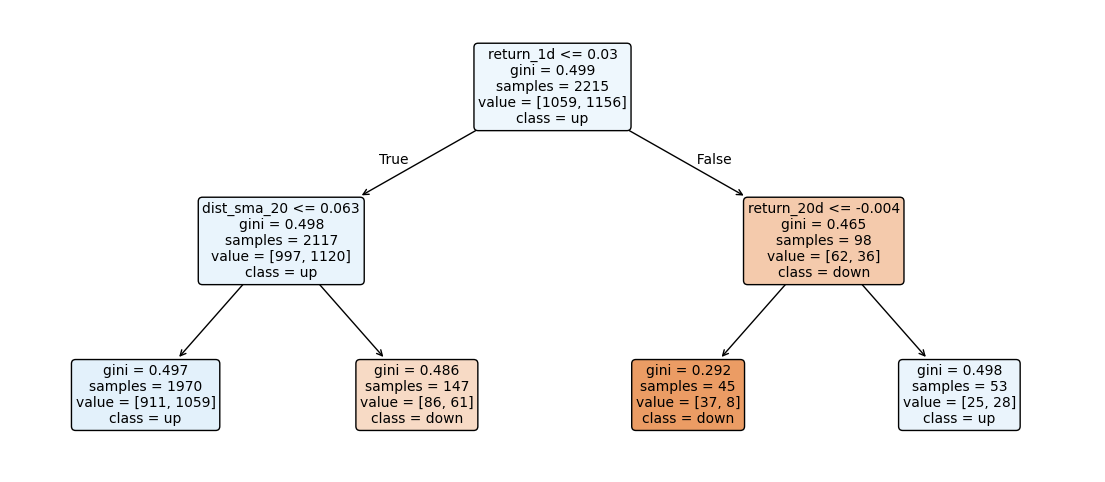

In [13]:
small_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
small_tree.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(small_tree, feature_names=FEATURES, class_names=["down", "up"],
          filled=True, rounded=True, fontsize=10, ax=ax)
plt.show()

That's the whole "intelligence": `fit()` searched for the **questions (feature + threshold)**
that split the training days into groups that are as "pure" as possible (mostly up or mostly down).

**A Random Forest** = many such trees (here 300), each one
- trained on a random sample of the days, and
- only allowed to look at a random subset of the features at each question.

At prediction time, **every tree votes** and the majority wins.
Individual trees make different mistakes — averaging cancels a lot of them out.

In [14]:
model = RandomForestClassifier(
    n_estimators=300,      # number of trees
    max_depth=4,           # how many questions each tree may ask (keeps trees simple)
    min_samples_leaf=20,   # every final group needs at least 20 days
    random_state=42,
    n_jobs=-1,
)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

---
## Step 7 — Evaluate honestly

In [15]:
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc  = accuracy_score(y_test,  model.predict(X_test))

print(f"Baseline (test):       {baseline_acc:.1%}")
print(f"Random Forest (train): {train_acc:.1%}")
print(f"Random Forest (test):  {test_acc:.1%}")

Baseline (test):       54.3%
Random Forest (train): 58.7%
Random Forest (test):  55.3%


**How to read this:**

- **Train accuracy** is how well the model fits the days it has *already seen*. That's easy.
- **Test accuracy** is the only number that matters: how good is it on *new* days?
- Compare test accuracy with the **baseline**. If they're about the same, the model has found no
  usable pattern — no matter how impressive the train number looks.

### Overfitting, made visible

What if we let the trees grow deeper — more questions, more detail?

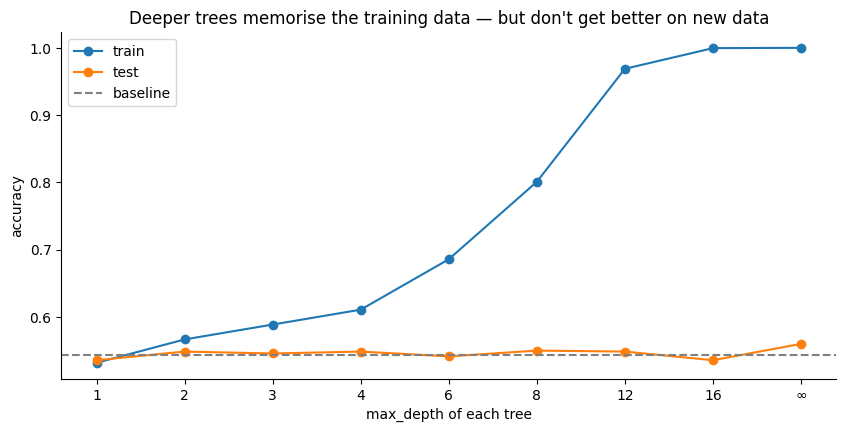

In [16]:
depths = [1, 2, 3, 4, 6, 8, 12, 16, None]
train_scores, test_scores = [], []

for d in depths:
    rf = RandomForestClassifier(n_estimators=200, max_depth=d, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, rf.predict(X_train)))
    test_scores.append(accuracy_score(y_test, rf.predict(X_test)))

labels = [str(d) if d else "∞" for d in depths]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(labels, train_scores, "o-", label="train")
ax.plot(labels, test_scores, "o-", label="test")
ax.axhline(baseline_acc, color="grey", ls="--", label="baseline")
ax.set_xlabel("max_depth of each tree")
ax.set_ylabel("accuracy")
ax.set_title("Deeper trees memorise the training data — but don't get better on new data")
ax.legend()
plt.show()

With unlimited depth the forest reaches ~100 % on training data: it has **memorised** every single day.
On the test data it gains nothing. That gap between the two lines is **overfitting**.

### Where does the model go wrong?

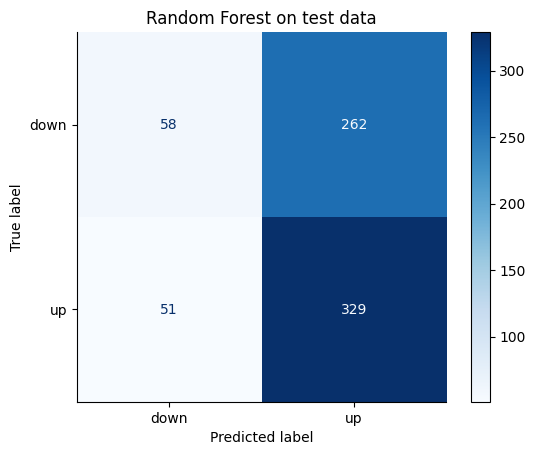

In [17]:
ConfusionMatrixDisplay.from_estimator(
    model, X_test, y_test, display_labels=["down", "up"], cmap="Blues"
)
plt.title("Random Forest on test data")
plt.show()

Rows = what really happened, columns = what the model predicted.
A model that (almost) always says "up" will have an almost empty left column — check whether that's the case here.

### Which features did the forest use?

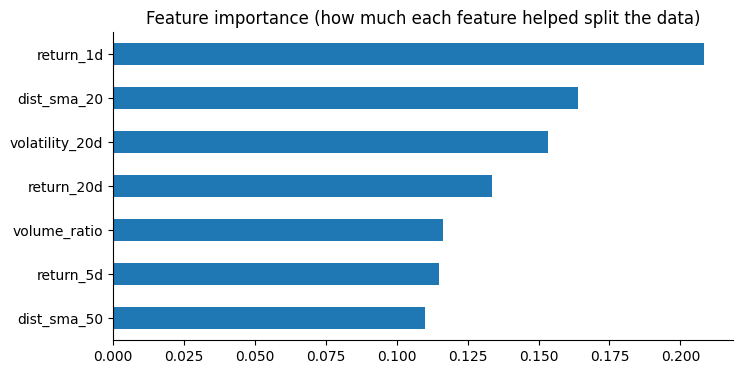

In [18]:
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
importance.plot.barh(figsize=(8, 4), title="Feature importance (how much each feature helped split the data)")
plt.show()

Careful: *importance* only says how often a feature was used to split the **training** data —
not that it actually predicts the future.

---
## Step 8 — Predict tomorrow

Remember `latest_day`, the row we put aside in Step 3? Its features are known, its target isn't.
This is what using a model looks like in practice: **new X in → prediction out.**

In [19]:
proba_up = model.predict_proba(latest_day)[0, 1]
prediction = "UP" if proba_up >= 0.5 else "DOWN"

print(f"Last known day: {latest_day.index[0].date()}, close = {df['close'].iloc[-1]:.2f} USD")
print(f"Model says for the next trading day: {prediction}  (P(up) = {proba_up:.1%})")

Last known day: 2026-10-16, close = 343.46 USD
Model says for the next trading day: UP  (P(up) = 52.9%)


`predict_proba` gives the share of trees voting "up". A value close to 50 % means the forest
is essentially undecided.

---
## Summary

| Step | What we did | sklearn |
|---|---|---|
| Data | prices from FMP | — |
| Features / target | X = what we know today, y = what happens tomorrow | — |
| Split | by time, never shuffle | — |
| Train | the model searches for patterns in X → y | `model.fit(X_train, y_train)` |
| Evaluate | on unseen data, against a baseline | `model.predict(X_test)` |
| Use | new X → prediction | `model.predict_proba(latest_day)` |

**The honest result:** predicting tomorrow's direction from past prices is extremely hard — markets
are close to random on a daily scale. If the forest barely beats (or doesn't beat) the baseline,
that's not a bug: it's the correct answer, and the reason we always evaluate on unseen data.

---
## Exercises

1. Change `SYMBOL` to another ticker (e.g. `MSFT`, `NVDA`, `SAP`). Does anything change?
2. Add a feature of your own (e.g. `return_60d`, or the day of the week). Does test accuracy improve?
3. Change the target to *"does the price rise more than 1 % within the next 5 days?"* — how does the baseline change?
4. **Leakage experiment:** add `close.shift(-1)` as a feature. What happens to test accuracy — and why is the model now worthless in practice?